# Subjectivity Mining — Assignment 5
## Group 9 · Martin · HateBERT probabilities and stacking

This is the completed Block 3 notebook. It includes two domain-specific stacking
ensembles, three-fold out-of-fold (OOF) base-model probabilities, six additional
text features, and a logistic-regression meta-model. The OLID test set is never
used to fit the meta-model or choose its settings.

The shipped results come from actual CUDA training and inference. Running this
notebook in its default mode reads and verifies those saved outputs; it does not
repeat the neural training. Training evidence is recorded in `training_stacking.log`,
`training_stacking_resumed.log` and `stacking_results/runs/`. The checkpoint archive
is not required to review results.

Use the source code and fresh output folder to reproduce training. Exact versions,
checkpoint revisions, folds, parameters and file hashes are included. The supplied
Ines/Helian files remain unchanged in `provided/`.

Dataset/error files contain offensive language. The final Pearson and qualitative
error analysis across all group approaches belongs to Pablos' integration block.


## 1. Setup

Keep the notebook, helper scripts, CSVs, `provided/` and `stacking_results/` in the
same folder. For reading saved outputs no GPU is needed. To install a fresh
training environment (tested with Python 3.12 and CUDA 12.4):

```python
%pip install torch==2.6.0 --index-url https://download.pytorch.org/whl/cu124
%pip install -r requirements.txt
```

Restart the runtime after installation. To reproduce all base-model training,
use a fresh copy of this folder with the saved `stacking_results/`, `base_models/`
and `meta_models/` moved aside, then run:

```sh
python a5_stacking.py
python evaluate_stacking.py
python verify_delivery.py --reload-base-models
```

The generator resumes verified completed tasks; it refuses to overwrite incomplete
full-model checkpoints. The delivered runs reused the original A4 HateBERT full-data
weights through `--a4-dir`, and trained BERT/fBERT full-data models. A fresh run without
that option also trains the two full-data HateBERT models. Colab can be used with a
GPU, but the delivered runs were executed locally and are not claimed as Colab runs.


In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
from a5_stacking import MODELS, PARAMS, PROB_COLUMNS, EXTRA_COLUMNS, text_features, load_data
from shared_evaluation import evaluate_predictions
ROOT = Path('.')
OUT = ROOT / 'stacking_results'
data = load_data(ROOT)
protocol = json.loads((OUT / 'prespecified_protocol.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model': name, 'checkpoint': value[0], 'revision': value[1]} for name,value in MODELS.items()]))


,model,checkpoint,revision
0,bert,google-bert/bert-base-uncased,86b5e0934494bd15c9632b12f734a8a67f723594
1,hatebert,GroNLP/hateBERT,ab7a2d40f6c973cb57e63f23bfa2b51d981d028c
2,fbert,diptanu/fBERT,c089daa35cb177238dd91ffe3010c2d8bbd069bf


## 2. Data and leakage controls

In-domain means OLID-small → OLID-test; cross-domain means HASOC → OLID-test.
Both training sets contain 5,852 examples. The common test set contains 860.
Labels are 0 = non-offensive and 1 = offensive.

The meta-training features are generated **only from the relevant training corpus**.
For every held-out fold, all three base models are newly initialized from their
original pretrained checkpoints and fitted on the other two folds. Exactly matching
texts are grouped to prevent duplicate text crossing a fold boundary. The same
fold memberships are used by all three models.

The prescribed OLID files already share three test texts with training. We preserve
the official files for group comparability and report this existing limitation.
Grouping controls leakage between stacking folds; it does not erase the supplied
train/test overlap or establish absence of overlap with pretraining corpora.


In [2]:
display(pd.read_csv(OUT / 'dataset_audit.csv'))
for setting in ['in_domain','cross_domain']:
    membership = pd.read_csv(OUT / f'folds_{setting}.csv')
    print(setting)
    display(membership.groupby('fold').labels.agg(n='size', offensive='sum'))


,dataset,rows,class_0,class_1,duplicate_text_rows,matching_test_texts
0,olid-train-small.csv,5852,3591,2261,8,3
1,hasoc-train.csv,5852,3591,2261,78,0


in_domain


,n,offensive
fold,,
0,1953,766
1,1948,747
2,1951,748


cross_domain


,n,offensive
fold,,
0,1944,761
1,1949,752
2,1959,748


## 3. HateBERT probabilities

The two saved A4 HateBERT checkpoints were reloaded for inference. The exported
probabilities match the values used in Helian's soft-voting files. No rounded hard
labels were converted into artificial probabilities.


In [3]:
for setting in ['in_domain','cross_domain']:
    ours = pd.read_csv(f'hatebert_probs_{setting}.csv')
    shared = pd.read_csv(f'provided/helian/results_soft_voting_{setting}.csv')
    assert ours[['id','text','labels']].equals(shared[['id','text','labels']])
    np.testing.assert_allclose(ours.probability_offensive, shared.hatebert_prob, atol=1e-7, rtol=0)
    assert ours.probability_offensive.between(0,1).all()
    np.testing.assert_allclose(ours.probability_offensive + ours.probability_non_offensive, 1)
    display(evaluate_predictions(ours.labels, ours.prediction, 'HateBERT', setting.replace('_','-').capitalize(), show_matrix=False).round(4))
print('HateBERT probability exports are verified.')


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,HateBERT,In-domain,0.8407,0.8022,0.8014,0.8018,0.8889,0.8903,0.8896,620,0.7155,0.7125,0.714,240


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,HateBERT,Cross-domain,0.8035,0.756,0.7513,0.7536,0.8596,0.8694,0.8645,620,0.6524,0.6333,0.6427,240


HateBERT probability exports are verified.


## 4. Prespecified model settings and extra features

Every newly fitted base model uses three epochs, learning rate 2e-5, effective batch
size 16, seed 42 and a 128-token limit. All parameters are fine-tuned. There is no
hyperparameter search, early stopping or test-based threshold adjustment.

The meta-model takes nine inputs: three offensive-class probabilities, log(1 +
character count), log(1 + word count), uppercase-letter fraction among alphabetic
characters, and counts of exclamation marks, question marks and hash characters.
These six surface features are extracted from the original text. They do not use
gold labels or a vocabulary learned from the test set.

StandardScaler is fitted on OOF training features. Logistic Regression then uses
C = 1, L2 regularization, the lbfgs solver, at most 2,000 iterations and no class
weighting. Each domain has its own fitted scaler and meta-model. The final class
comes from the standard logistic-regression decision rule, without tuning a threshold.


In [4]:
display(pd.DataFrame([PARAMS]).T.rename(columns={0:'value'}))
print('Probability columns:', PROB_COLUMNS)
print('Additional columns:', EXTRA_COLUMNS)
display(text_features(data['olid-test.csv'].text.head(5)))


,value
num_train_epochs,3
learning_rate,0.00002
train_batch_size,8
gradient_accumulation_steps,2
eval_batch_size,32
max_seq_length,128
optimizer,AdamW
scheduler,linear_schedule_with_warmup
warmup_ratio,0.06
warmup_steps,0


Probability columns: ['bert_prob', 'hatebert_prob', 'fbert_prob']
Additional columns: ['log_characters', 'log_words', 'uppercase_fraction', 'exclamation_count', 'question_count', 'hashtag_count']


,log_characters,log_words,uppercase_fraction,exclamation_count,question_count,hashtag_count
0,5.505332,3.332205,0.302564,3,0,7
1,4.718499,2.639057,0.063830,0,0,1
2,5.323010,3.367296,0.496599,0,0,14
3,4.941642,3.178054,0.101852,0,0,3
4,4.595120,2.890372,0.140845,1,0,4


## 5. Fit/reproduce the meta-models from saved OOF probabilities

The following cell fits the inexpensive meta-models again using the **training OOF
files**, reproduces saved test results, and runs the provenance checks. Neural
training is not repeated. The probability-only ablation was specified before
examining results and is reported as a diagnostic, not selected as the primary model.


In [5]:
from evaluate_stacking import evaluate
all_metrics = evaluate(ROOT)
from verify_delivery import verify
verification = verify(ROOT, reload_base_models=False)
print('Verification status:', verification['status'])


   model      setting  accuracy  macro_precision  macro_recall  macro_f1  precision_0  recall_0     f1_0  support_0  precision_1  recall_1     f1_1  support_1
Stacking    In-domain  0.855814         0.823396      0.813172  0.818001     0.892405  0.909677 0.900958        620     0.754386  0.716667 0.735043        240
Stacking Cross-domain  0.851163         0.830951      0.783132  0.801550     0.867164  0.937097 0.900775        620     0.794737  0.629167 0.702326        240


Verified OOF provenance, fixed test rows, supplied metrics and saved meta-model reloads.


Delivery verification passed.


Verification status: passed


## 6. Stacking results

The same evaluation function as Ines' notebook is used: macro P/R/F1, per-class
P/R/F1, accuracy and confusion matrices. Rows of the matrices are true labels;
columns are predictions, ordered [0, 1].


,model,setting,accuracy,macro_precision,macro_recall,macro_f1,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1
0,Stacking,In-domain,0.8558,0.8234,0.8132,0.8180,0.8924,0.9097,0.9010,620,0.7544,0.7167,0.7350,240
1,Stacking,Cross-domain,0.8512,0.8310,0.7831,0.8016,0.8672,0.9371,0.9008,620,0.7947,0.6292,0.7023,240


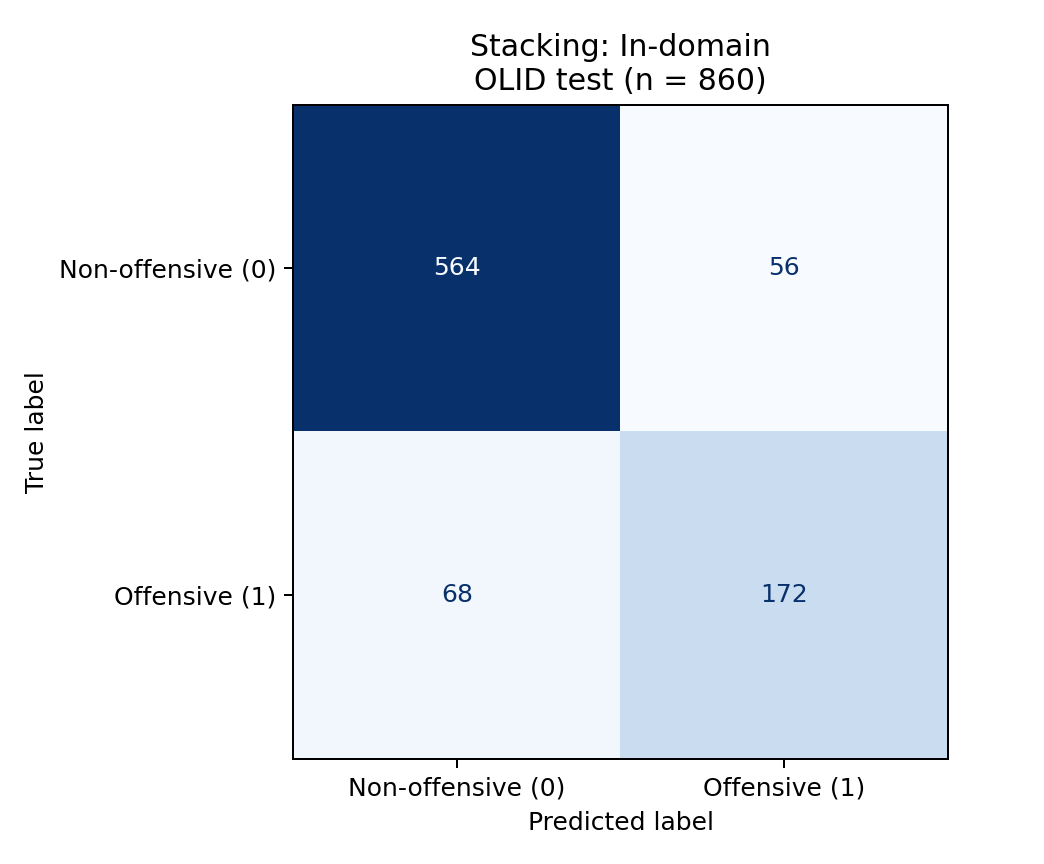

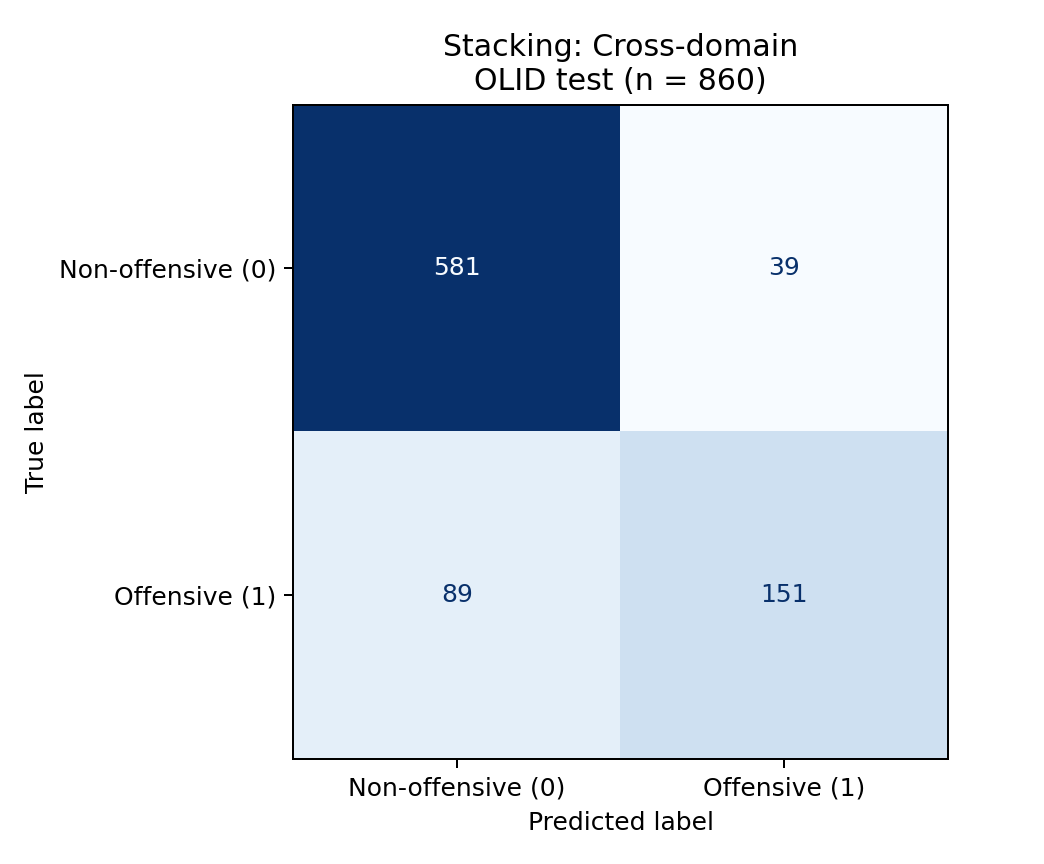

,model,macro_f1_in_domain,macro_f1_cross_domain,absolute_drop,percentage_point_drop,relative_drop_percent
0,Stacking,0.818,0.8016,0.0165,1.645,2.011


In [6]:
stacking = pd.read_csv(OUT / 'metrics_stacking_comparison.csv')
display(stacking.round(4))
for setting in ['in_domain','cross_domain']:
    display(Image(filename=str(OUT / f'confusion_stacking_{setting}.png')))
changes = pd.read_csv(OUT / 'domain_changes.csv')
display(changes[changes.model == 'Stacking'].round(4))


## 7. Compare ensemble strategies with the base-model pool held fixed

The supplied Ines and Helian blocks use different BERT fits: their BERT hard
predictions differ on 76 test examples in-domain and 132 cross-domain. Our primary
comparison recomputes hard and soft voting using exactly the full-data models
used for stacking. This isolates the ensemble rule more clearly.

The original teammate results remain in the all-comparisons CSV, with an explicit
`pool` column. Their original scores should not be silently substituted for the
matched-pool figures. The shared-pool stacking sensitivity also has a separate
label, since its BERT/fBERT full-model fits do not match those producing the OOF
training features. It is not the primary experiment.


,model,setting,macro_precision,macro_recall,macro_f1
0,Stacking,In-domain,0.8234,0.8132,0.8180
1,Stacking (probabilities only),In-domain,0.8209,0.8090,0.8146
2,bert,In-domain,0.8002,0.7947,0.7973
3,hatebert,In-domain,0.8022,0.8014,0.8018
4,fbert,In-domain,0.8136,0.8071,0.8102
5,Hard voting (matched),In-domain,0.8103,0.8054,0.8078
6,Soft voting (matched),In-domain,0.8276,0.8181,0.8226
7,Stacking,Cross-domain,0.8310,0.7831,0.8016
8,Stacking (probabilities only),Cross-domain,0.8341,0.7793,0.7997
9,bert,Cross-domain,0.7648,0.7274,0.7415


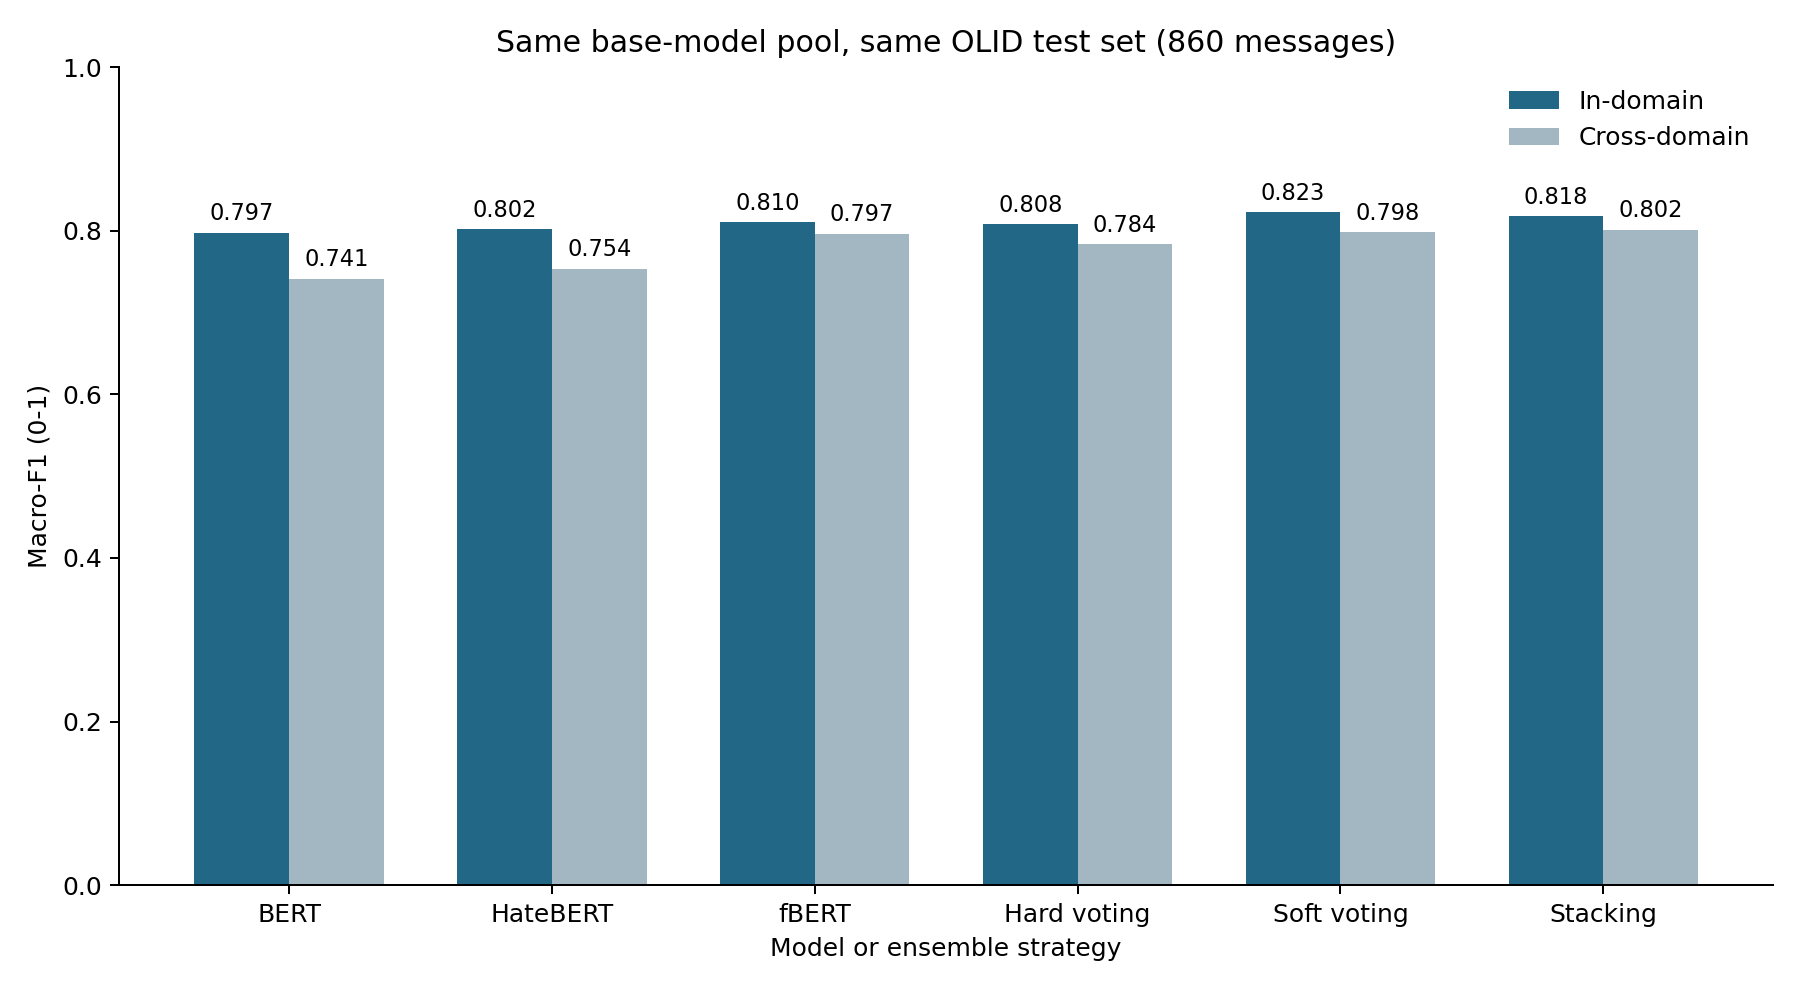

,model,setting,pool,macro_f1
7,Hard voting (Ines),In-domain,Provided A4 labels,0.8018
8,Soft voting (Helian),In-domain,Provided Helian probabilities,0.8030
9,Stacking (shared-pool sensitivity),In-domain,Shared pool; base-fit mismatch,0.8121
17,Hard voting (Ines),Cross-domain,Provided A4 labels,0.7863
18,Soft voting (Helian),Cross-domain,Provided Helian probabilities,0.7813
19,Stacking (shared-pool sensitivity),Cross-domain,Shared pool; base-fit mismatch,0.7928


In [7]:
matched = pd.read_csv(OUT / 'metrics_matched_pool_comparison.csv')
display(matched[['model','setting','macro_precision','macro_recall','macro_f1']].round(4))
display(Image(filename=str(OUT / 'matched_model_comparison.png')))
display(all_metrics[all_metrics.pool != 'Matched A5'][['model','setting','pool','macro_f1']].round(4))


## 8. What did the additional features change?

We report a probability-only stacking ablation using the same OOF probabilities
and fixed logistic-regression settings. The primary model remains the specified
nine-feature model regardless of which test score is larger. Coefficients are
standardized associations, not causal feature importance; the base probabilities
can be strongly correlated.


In [8]:
display(matched[matched.model.str.startswith('Stacking')][['model','setting','macro_f1']].round(4))
display(pd.read_csv(OUT / 'meta_coefficients.csv').round(4))


,model,setting,macro_f1
0,Stacking,In-domain,0.8180
1,Stacking (probabilities only),In-domain,0.8146
7,Stacking,Cross-domain,0.8016
8,Stacking (probabilities only),Cross-domain,0.7997


,setting,feature,standardized_coefficient
0,In-domain,bert_prob,0.1398
1,In-domain,hatebert_prob,0.1913
2,In-domain,fbert_prob,1.3579
3,In-domain,log_characters,-0.3121
4,In-domain,log_words,0.2956
5,In-domain,uppercase_fraction,-0.0670
6,In-domain,exclamation_count,0.0105
7,In-domain,question_count,0.1033
8,In-domain,hashtag_count,0.0043
9,Cross-domain,bert_prob,0.3194


## 9. Quantitative errors and handoff for qualitative analysis

The full error CSVs preserve IDs, text, gold labels and predictions. A reproducible
sample of ten false positives and ten false negatives (seed 42) is supplied for
Pablos' qualitative review. The sample is not a frequency estimate of error types.
Pearson analysis and selection of the group ensemble for detailed qualitative
analysis remain part of the final integration.


In [9]:
display(pd.read_csv(OUT / 'error_summary_stacking.csv').round(4))
display(pd.read_csv(OUT / 'errors_by_length_stacking.csv').round(4))
sample = pd.read_csv(OUT / 'cross_domain_review_sample.csv')
display(sample[['id','labels','prediction','error_type','text']])


,setting,TN,FP,FN,TP,false_positive_rate,false_negative_rate
0,In-domain,564,56,68,172,0.0903,0.2833
1,Cross-domain,581,39,89,151,0.0629,0.3708


,setting,length_group,n,offensive_support,errors,error_rate
0,In-domain,0-15 words,275,89,39,0.1418
1,In-domain,16-30 words,305,86,42,0.1377
2,In-domain,31+ words,280,65,43,0.1536
3,Cross-domain,0-15 words,275,89,34,0.1236
4,Cross-domain,16-30 words,305,86,50,0.1639
5,Cross-domain,31+ words,280,65,44,0.1571


,id,labels,prediction,error_type,text
0,15815,1,0,false_negative,#BelieveAllWomen just when I think things can'...
1,22594,1,0,false_negative,@USER @USER @USER Fascism was also against lib...
2,47445,1,0,false_negative,". JEFF SESSIONS: ‘LISTEN TO THE ACLU, ANTIFA, ..."
3,52445,1,0,false_negative,#Elitist #Actors #NBC #Liberals of #Dems in #H...
4,58026,1,0,false_negative,#MAGA #Qanon #GreatAwakening #inners #WWG1WGA ...
5,60133,1,0,false_negative,#NoPasaran: Unity demo to oppose the far-right...
6,62689,1,0,false_negative,#scottgimple ruined #TheWalkingDead and now he...
7,72531,1,0,false_negative,#GoodMorningAmerica #TuesdayMotivation #Thank...
8,80397,1,0,false_negative,#Liberals Are Reaching Peak Desperation To Cal...
9,83466,1,0,false_negative,#Beeto Just Demonstrated How To Lose An Electi...


## 10. Report and integration

Read `A5-Martin-Stacking-report.pdf` (or the Markdown/HTML version) for the completed
write-up. `A5-Martin-Stacking.tex` contains the integration fragments, and
`INTEGRATION_FOR_PABLOS.md` explains the probability files, metric imports and
model-pool distinction. `A5-Martin-references.bib` contains the references.

**Martin's contribution:** HateBERT probability export and verification; OOF feature
generation for stacking; implementation, execution and quantitative analysis of
the stacking ensembles; saved-model checks and report preparation.

References: Wolpert (1992), [Stacked generalization](https://doi.org/10.1016/S0893-6080(05)80023-1);
Caselli et al. (2021), [HateBERT](https://aclanthology.org/2021.woah-1.3/);
van Aken et al. (2018), [Challenges for Toxic Comment Classification](https://aclanthology.org/W18-5105/).
